# 03 - Baseline and Bagging (Random Forest, Extra Trees)
**Baseline - Ridge regression.** A simple linear model on the same encoded features. Every ensemble must beat it to justify its extra complexity.

**Bagging (bootstrap aggregating)** trains many trees independently and **averages** their predictions. Deep decision trees have low bias but high variance; averaging many de-correlated trees keeps the low bias and cuts the variance.
- **Random Forest:** each tree sees a bootstrap sample of the rows and a random subset of features at each split.
- **Extra Trees:** same idea, but split points are also chosen at random, which de-correlates the trees even more (faster, slightly more bias).



In [1]:
import sys, warnings
sys.path.append("..")                      # lets the notebook import the reusable code in ../src
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, preprocess as P, models as M
from src.evaluate import regression_metrics, permutation_table
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
config.PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
splits = P.load_splits()                   # same rows in every notebook (created in notebook 02)
X_tr, y_tr = P.xy(splits["train"])
X_va, y_va = P.xy(splits["val"])
print(len(X_tr), "train rows |", len(X_va), "validation rows")

3102 train rows | 665 validation rows


## 1. Baseline: Ridge regression
Ridge Regression is trained as the baseline model.
It makes predictions using the validation dataset. Its performance is measured using regression metrics such as MAE, RMSE, and R². The ensemble models are compared against this baseline.

In [3]:
ridge = M.make_ridge().fit(X_tr, y_tr)
p_ridge = ridge.predict(X_va)
pd.Series(regression_metrics(y_va, p_ridge), name="Ridge baseline (validation)").to_frame()

,Ridge baseline (validation)
MAE,"21,229.87"
RMSE,"42,128.03"
R2,0.81
MAPE_%,32.61
MedianAE,"9,608.32"


## 2. Tune on the training set
This section provides optional hyperparameter tuning for Random Forest and Extra Trees. It uses randomized search with 3-fold cross-validation on the training data. Tuning is disabled by default to reduce execution time.

Set `RUN_TUNING = True` to run a 3-fold randomised search (training data only). The best parameters are stored in `outputs/best_params.json` and picked up automatically by every notebook.

In [7]:
RUN_TUNING = False
if RUN_TUNING:
    for name in ["random_forest", "extra_trees"]:
        best, cv_mae, _ = M.tune(name, X_tr, y_tr, n_iter=12)
        print(name, "best params:", best, "| CV MAE:", round(cv_mae))
print("RF params in use:", {k: v for k, v in M.rf_regressor().get_params().items() if k in ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]})

RF params in use: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 200}


## 3. Random Forest - train and evaluate on the validation set
Trains the Random Forest model and evaluates its predictions using the validation dataset. The scatter plot compares actual and predicted prices, while the residual histogram shows the prediction errors.

In [8]:
rf = M.make_random_forest()          # preprocessing + RandomForestRegressor, trained on log(price)
rf.fit(X_tr, y_tr)
pred = rf.predict(X_va)
pd.Series(regression_metrics(y_va, pred), name="Random Forest (validation)").to_frame()

,Random Forest (validation)
MAE,"17,139.68"
RMSE,"33,975.96"
R2,0.87
MAPE_%,29.43
MedianAE,"8,361.19"


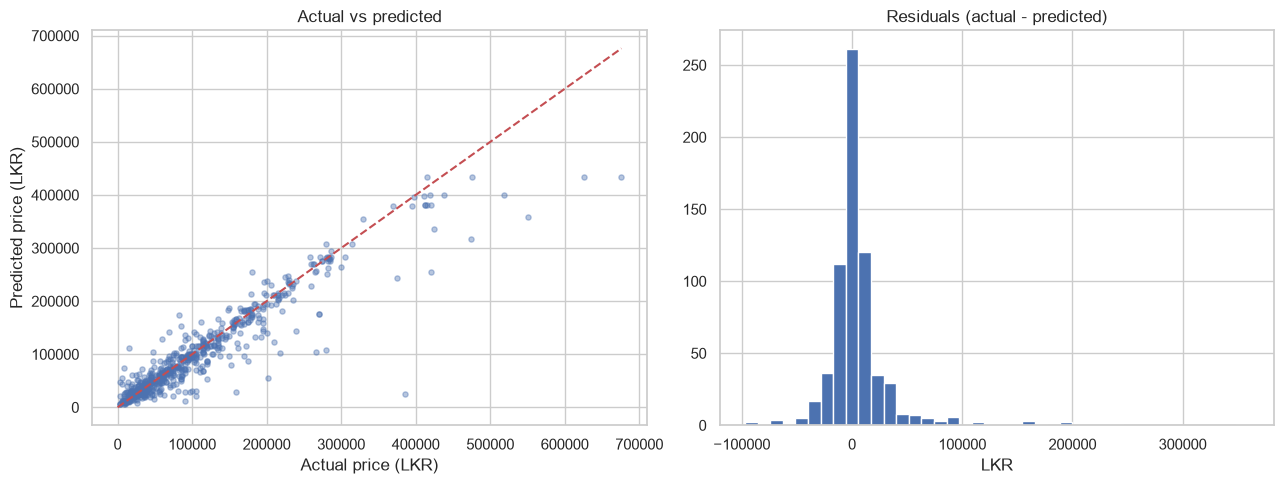

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_va, pred, alpha=.4, s=14); lim = [0, max(y_va.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual price (LKR)"); ax[0].set_ylabel("Predicted price (LKR)"); ax[0].set_title("Actual vs predicted")
ax[1].hist(y_va - pred, bins=40, color="#4C72B0"); ax[1].set_title("Residuals (actual - predicted)"); ax[1].set_xlabel("LKR")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "03_rf_actual_vs_pred.png", dpi=150); plt.show()

## 4. Extra Trees and the comparison with Ridge
 trains the Extra Trees model and compares it with Ridge Regression and Random Forest. The comparison table shows the validation performance of all three models using the same evaluation metrics.

In [10]:
et = M.make_extra_trees().fit(X_tr, y_tr)
p_et = et.predict(X_va)
pd.DataFrame({"Ridge baseline": regression_metrics(y_va, p_ridge), "Random Forest": regression_metrics(y_va, pred),
              "Extra Trees": regression_metrics(y_va, p_et)}).T

,MAE,RMSE,R2,MAPE_%,MedianAE
Ridge baseline,"21,229.87","42,128.03",0.81,32.61,"9,608.32"
Random Forest,"17,139.68","33,975.96",0.87,29.43,"8,361.19"
Extra Trees,"18,630.32","35,504.95",0.86,33.15,"9,842.23"


## 5. Why bagging works: error vs number of trees
 examines how the number of trees affects Random Forest performance. It calculates training and validation MAE for different numbers of trees and plots the results to observe changes in prediction error.

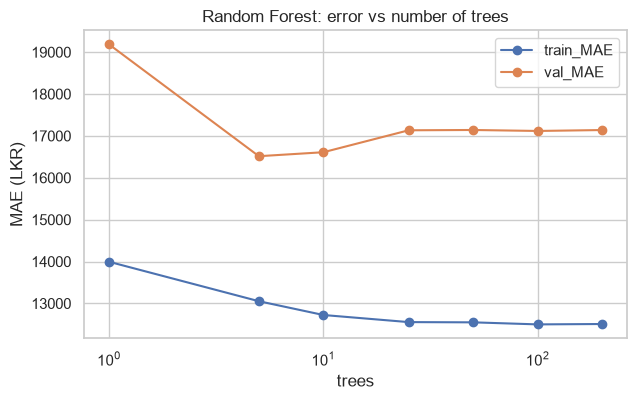

,trees,val_MAE,train_MAE
0,1,"19,184.50","13,994.25"
1,5,"16,515.13","13,052.73"
2,10,"16,609.76","12,723.49"
3,25,"17,133.71","12,553.91"
4,50,"17,140.98","12,548.24"
5,100,"17,117.66","12,499.25"
6,200,"17,139.68","12,508.32"


In [11]:
rows = []
for k in [1, 5, 10, 25, 50, 100, 200]:
    m = M.make_random_forest(n_estimators=k).fit(X_tr, y_tr)
    rows.append({"trees": k, "val_MAE": regression_metrics(y_va, m.predict(X_va))["MAE"],
                 "train_MAE": regression_metrics(y_tr, m.predict(X_tr))["MAE"]})
curve = pd.DataFrame(rows)
curve.plot(x="trees", y=["train_MAE", "val_MAE"], marker="o", figsize=(7, 4), logx=True)
plt.ylabel("MAE (LKR)"); plt.title("Random Forest: error vs number of trees")
plt.savefig(config.PLOT_DIR / "03_rf_trees_curve.png", dpi=150); plt.show()
curve

## 6. Which features matter?
 identifies the features that contribute most to the Random Forest model's predictions. It calculates grouped feature importance and displays the results as a bar chart.

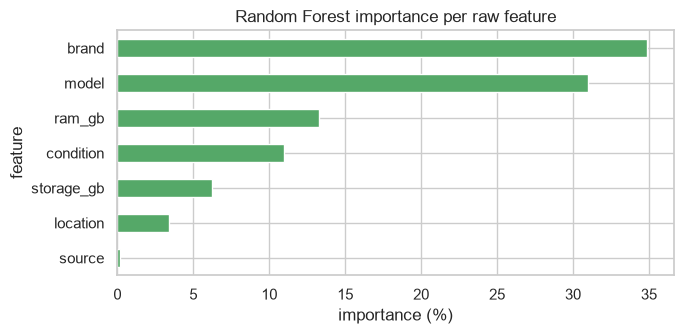

,feature,importance_%
0,brand,34.90
1,model,30.96
2,ram_gb,13.28
3,condition,11.00
4,storage_gb,6.25
5,location,3.42
6,source,0.18


In [12]:
from src.explain import grouped_importance
imp = grouped_importance(rf)
imp.sort_values("importance_%").plot.barh(x="feature", y="importance_%", legend=False, figsize=(7, 3.5), color="#55A868")
plt.xlabel("importance (%)"); plt.title("Random Forest importance per raw feature"); plt.tight_layout()
plt.savefig(config.PLOT_DIR / "03_rf_feature_importance.png", dpi=150); plt.show()
imp

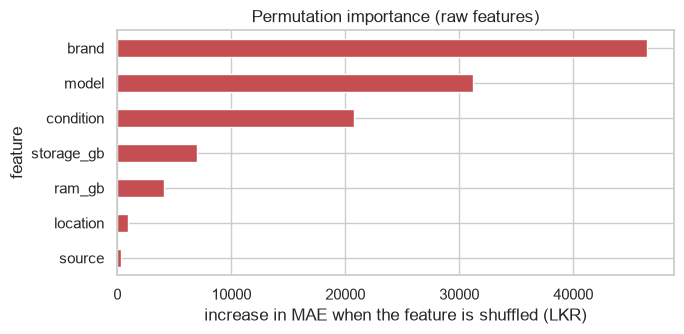

,feature,mae_increase,std
0,brand,"46,508.12","1,182.96"
1,model,"31,232.53",663.34
2,condition,"20,766.26","1,788.22"
5,storage_gb,"6,963.96",639.49
6,ram_gb,"4,108.63",302.34
3,location,947.18,315.36
4,source,295.44,8.14


In [13]:
pi = permutation_table(rf, X_va, y_va)
pi.sort_values("mae_increase").plot.barh(x="feature", y="mae_increase", legend=False, figsize=(7, 3.5), color="#C44E52")
plt.xlabel("increase in MAE when the feature is shuffled (LKR)"); plt.title("Permutation importance (raw features)")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "03_rf_permutation_importance.png", dpi=150); plt.show()
pi

## 7. Note

- **Baseline vs Random Forest:** Random Forest performs better than Ridge, reducing MAE by 19% and improving R² from 0.81 to 0.87.
- **Random Forest vs Extra Trees:** Random Forest performs better, with lower MAE and higher R².
- **Bagging:** Averaging multiple trees reduces prediction error by about 11% compared to a single tree. Performance becomes stable after around 25 trees.
- **Over-fitting:** Training MAE is lower than validation MAE, showing some over-fitting, but the gap remains stable.
- **Important features:** Brand (35%) and model (31%) are the most important features, followed by RAM, condition and storage. Source has very little impact. Permutation importance also confirms brand and model as the top features.